# Generate plots of Radio Sources Occultation based on ExPRES simulations

This notebook reads an ExPRES CDF and flyby ephemerides, then creates synthesized dynamic spectrum of the occulted radio sources

## Workflow

1. Enter Spacecraft and flyby names.
2. If the flyby is not already configured, add it to the required JSON files as described below.
3. Provide the ExPRES CDF when prompted.
4. Choose the frequency to look at in individual source-type plots. 
5. Produce individual source-type occultation plot and the synthesized dynamic spectrum (for each and all source-type).

In [1]:
import occultation

from pathlib import Path
import importlib
import json

from matplotlib import pyplot as plt
%matplotlib inline
import matplotlib.dates as mdates
ticks_30min = mdates.MinuteLocator(interval=30)
ticks_10min = mdates.MinuteLocator(interval=10)
dateFmt = mdates.DateFormatter('%H:%M')


current_dir = Path.cwd().resolve()
root_path = next(
    (path for path in (current_dir, *current_dir.parents)
     if (path / "cosmographia.ipynb").is_file()),
    None,
)
if root_path is None:
    raise FileNotFoundError(
        "Unable to find cosmographia.ipynb in the current directory "
        f"or its parents ({current_dir})."
    )

from cosmographia_utils import load_mission_config

/Users/clouis/anaconda3/envs/python3.8/lib/python3.8/site-packages/spacepy/time.py:2341: UserWarning: Leapseconds may be out of date. Use spacepy.toolbox.update(leapsecs=True)
  warnings.warn('Leapseconds may be out of date.'


In [2]:
Spacecraft_name = input("Please enter spacecraft name (for JUICE, enter JUICE): ").strip()
flyby_name = input("Please enter flyby name: ").strip()

## Add a Flyby to `flybys_list.json` (if missing)

If the selected flyby is not listed, add an entry keyed by its flyby name. Each entry must define:

- `spacecraft`: the mission name exactly as listed in `spacecraft.json` (for example, `JUICE`, `Juno`, `GLL`, or `Cassini`).
- `moon`: the target moon name used by the ephemeris configuration (for example, `Europa` or `Ganymede`).
- `start_time` and `end_time`: the flyby time interval in ISO format `YYYY-MM-DDTHH:mm:ss`.

The next cell can create this entry interactively. Check the names and UTC times before continuing; `occultation.py` reads these values when the flyby object is created.

In [5]:
with open("flybys_list.json") as f:
    flyblys_list_json = json.load(f)

if flyby_name not in flyblys_list_json.keys():
    moon_input = input("Please enter the moon involved in the flyby: ")
    start_time_input = input("Please enter the START time of the flyby (format: YYYY-MM-DDTHH:mm:ss): ")
    end_time_input = input("Please enter the END time of the flyby (format: YYYY-MM-DDTHH:mm:ss): ")
    flyblys_list_json[f'{flyby_name}'] = {
        'spacecraft': f'{Spacecraft_name}',
        'moon': f'{moon_input}',
        'start_time': f'{start_time_input}',
        'end_time': f'{end_time_input}'
    }
    with open("flybys_list.json", "w") as f:
        json.dump(flyblys_list_json, f)



## Adding Ephemerides to `ephem-wgc.json` (if missing)

If the flyby is not listed, add an entry keyed by its flyby name. It must map the spacecraft name and moon name from `flybys_list.json` to their corresponding WebGeocalc state-vector CSV files. Store both CSV files in the project's `ephem/` directory; when prompted, enter each filename relative to that directory, without the `ephem/` prefix.

For example, a JUICE flyby of Europa should contain keys `JUICE` and `Europa`, with values such as `ephem/juice_state_vector.csv` and `ephem/europa_state_vector.csv`. The names must match the spacecraft and moon fields in `flybys_list.json` exactly. The next cell creates a basic entry if the flyby is absent; verify the generated JSON paths before continuing.

Ephemeris files need to follow the Webgeocal format (see `file_exemple.csv`) - csv output webgeocalc

In [6]:
with open("ephem-wgc.json") as f:
    ephem_wgc_json = json.load(f)

if flyby_name not in ephem_wgc_json.keys():
    moon_input = input("Please enter the moon involved in the flyby: ")
    ephem_moon_input = input("Please enter the Moon ephemeris file corresponding to the flyby (the one you used for the occultation pipeline)")
    ephem_spacecraft_input = input("Please enter the Spacecraft ephemeris file corresponding to the flyby (the one you used in ExPRES and for the occultation pipeline)")
    print("PLEASE STORE BOTH OF YOUR EPHEMERIS FILE IN THE ephem directory")
    ephem_wgc_json[f'{flyby_name}'] = {
            f'{Spacecraft_name}': f'ephem/{ephem_spacecraft_input}',
            f'{moon_input}': f'ephem/{ephem_moon_input}',
        }
    with open("ephem-wgc.json", "w") as f:
        json.dump(ephem_wgc_json, f)

# flyby_table = get_flyby_table()

## Loading and Reading CDF file

The code will ask you to enter the full path and name of the ExPRES CDF containing source positions

In [ ]:
expres_cdf = {}
cdf_file_path = input(
    "Please enter the full path and name of the ExPRES CDF containing source positions: "
).strip()
if not Path(cdf_file_path).is_file():
    raise FileNotFoundError(f"ExPRES CDF not found: {cdf_file_path}")


In [46]:
frequency_to_look_at = float(input("Please enter the frequency to look at for individual plots (all frequency will be displayed in the final plots)")) or float(10)

In [47]:
# Reload occultation so flybys and ephemerides added above are visible.
occultation = importlib.reload(occultation)


(7201, 19, 720)
0.00847618146372137
0.15269527810503158
this is the distance to the flyby target


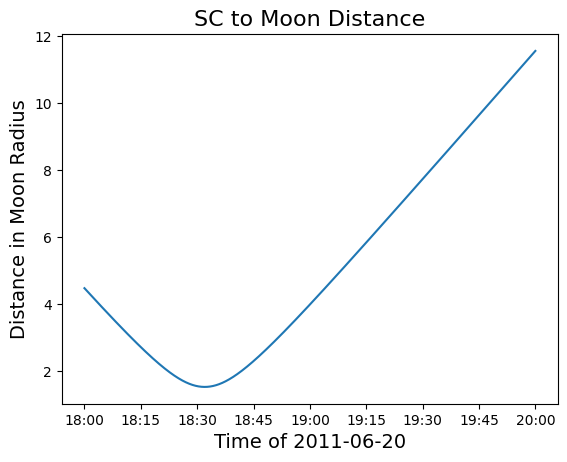

this is the distance to the radio sources


/Users/clouis/anaconda3/envs/python3.8/lib/python3.8/site-packages/numpy/ma/core.py:6957: RuntimeWarning: overflow encountered in power
  result = np.where(m, fa, umath.power(fa, fb)).view(basetype)


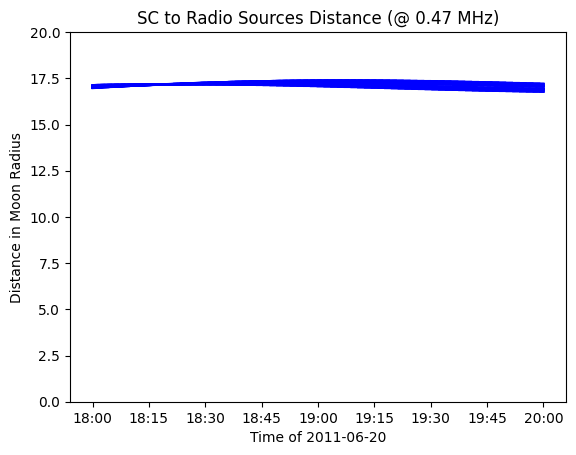

this is the intercept distance at the default 
 If a line goes below 1 
 if the line is blue there should be an occultation 
 if the line is grey the spacecraft is located in-between the sources and the moon


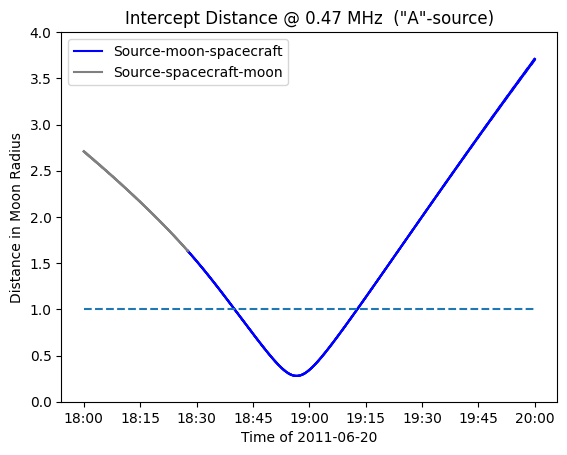

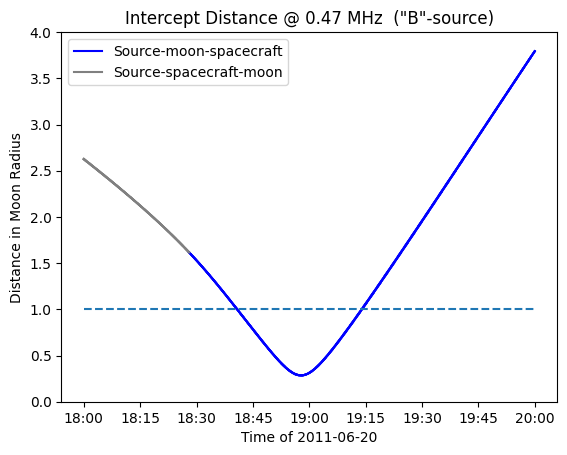

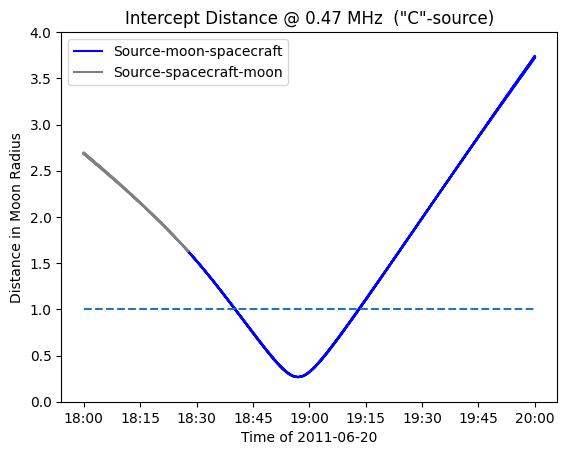

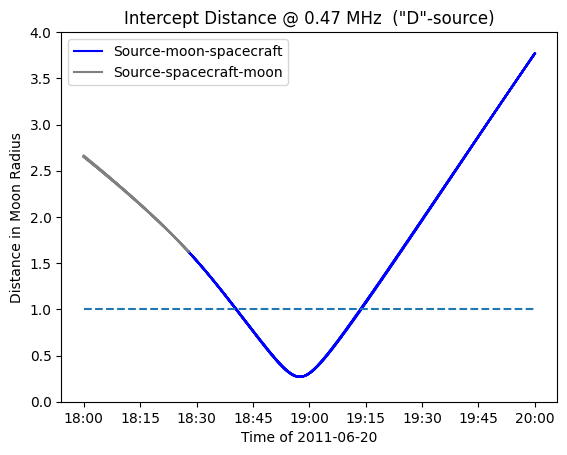

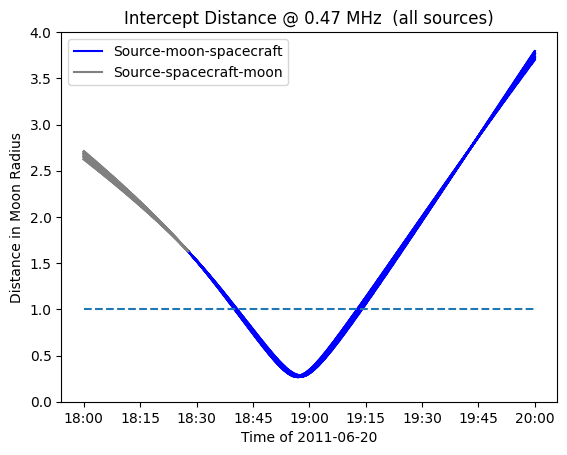

136819
(7201, 19)
The occultation radius is set to 1.0 (1 = no atmosphere)
1.0 99885.0
1.0 99123.0


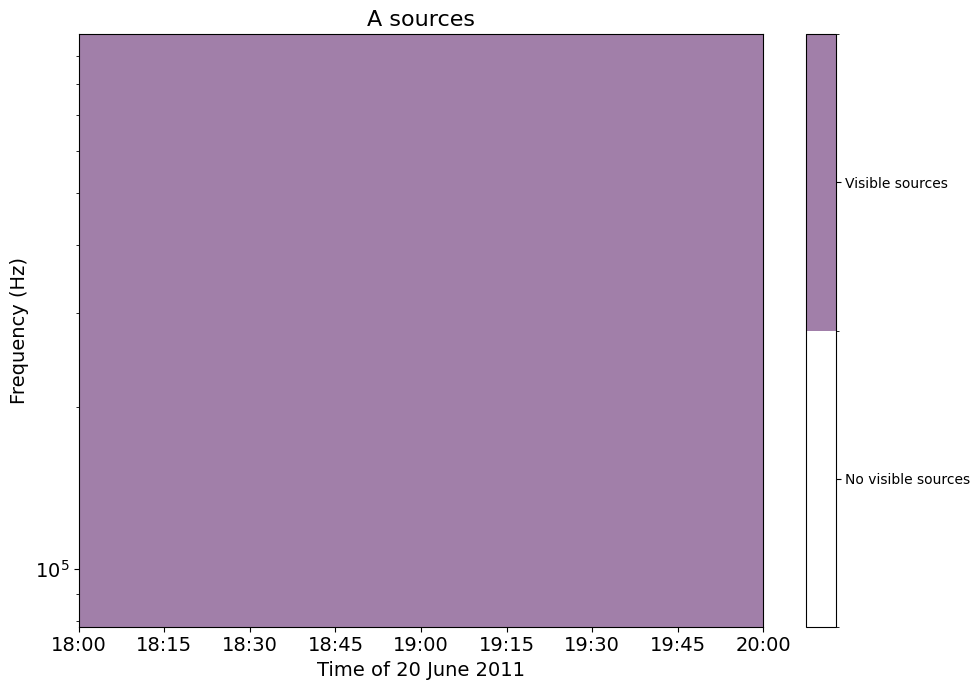

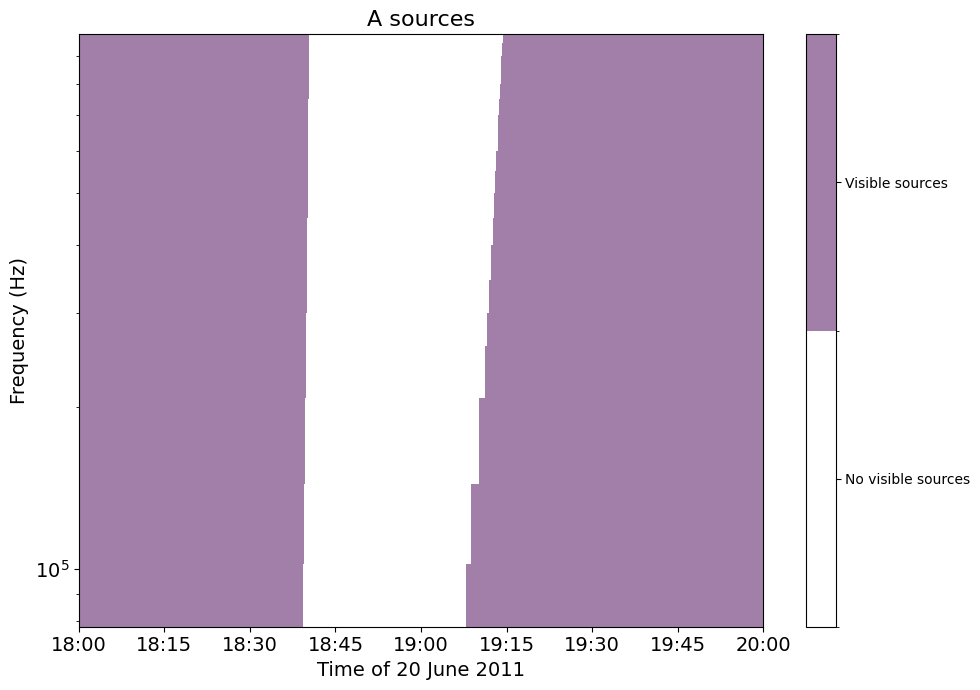

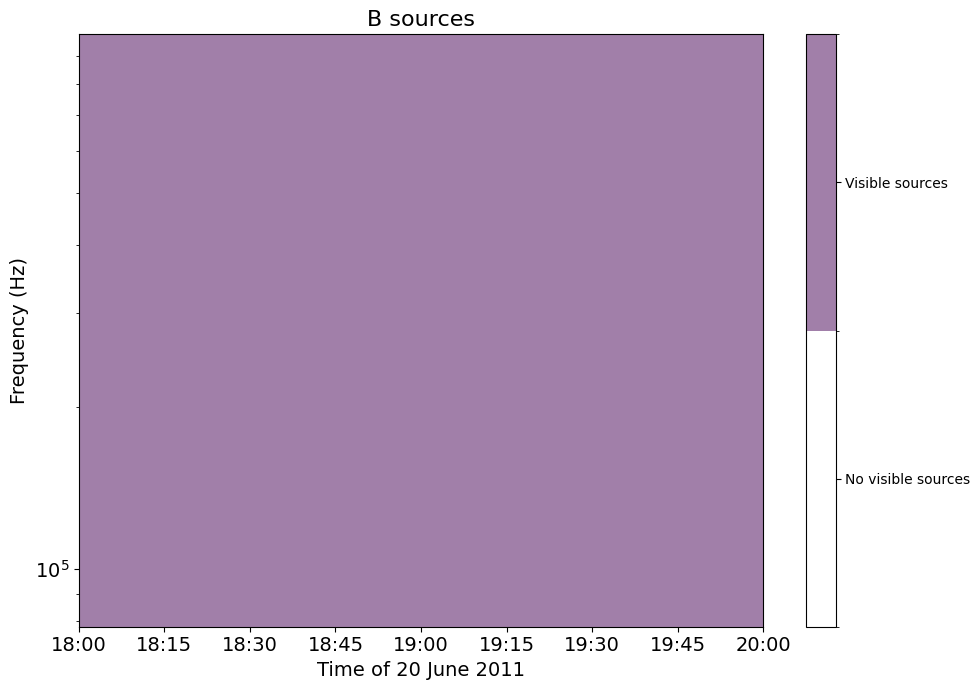

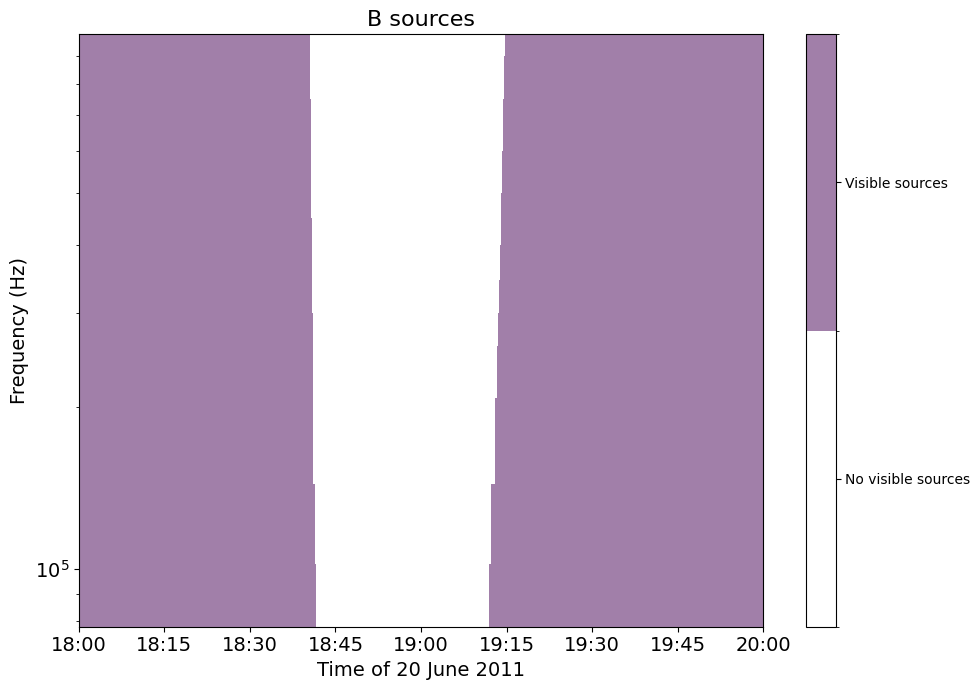

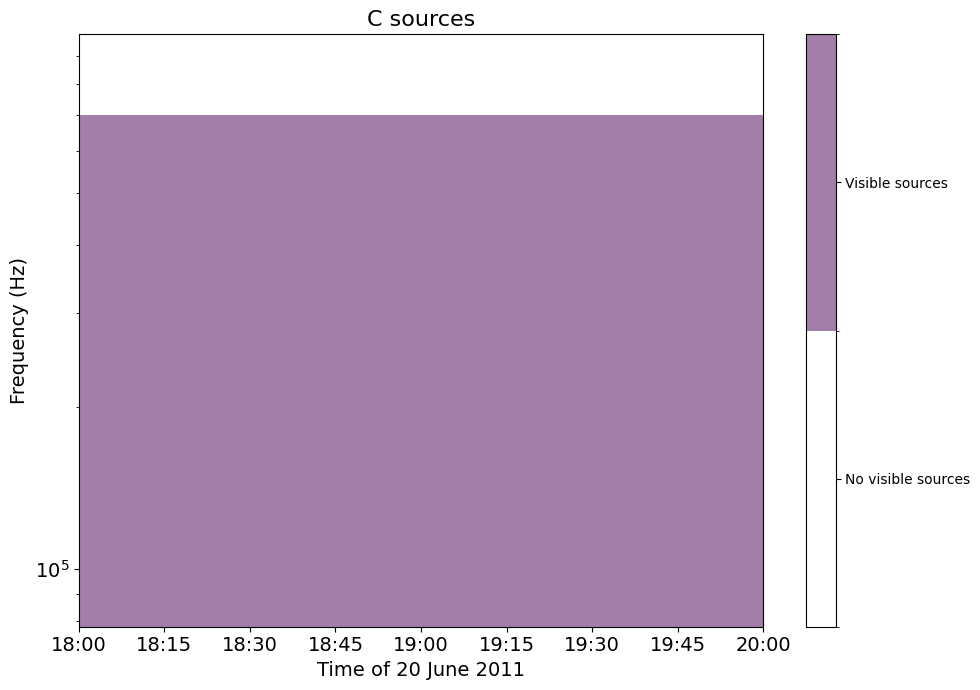

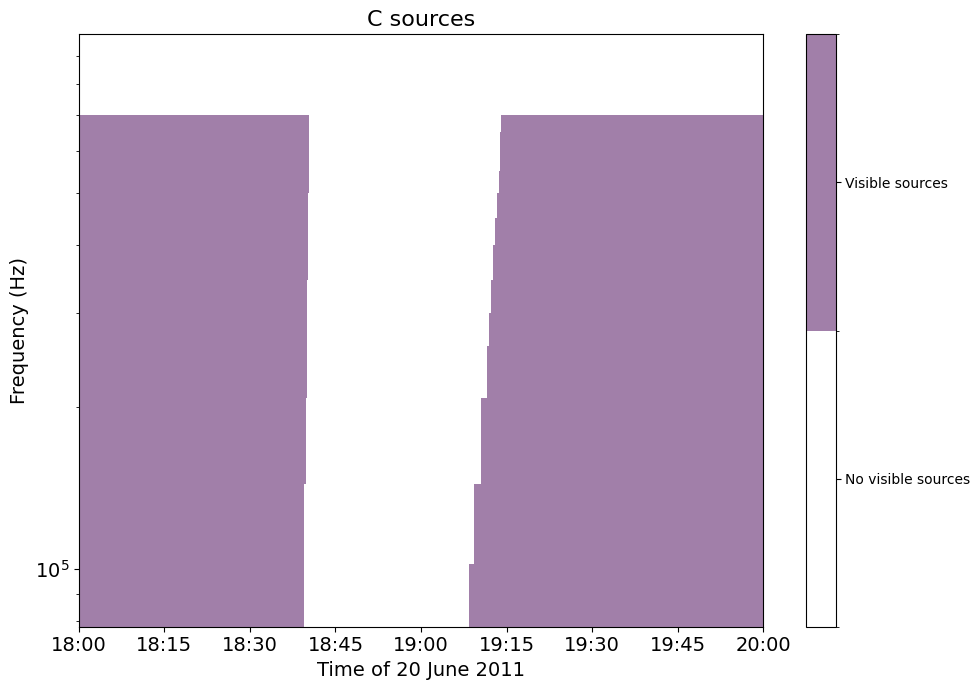

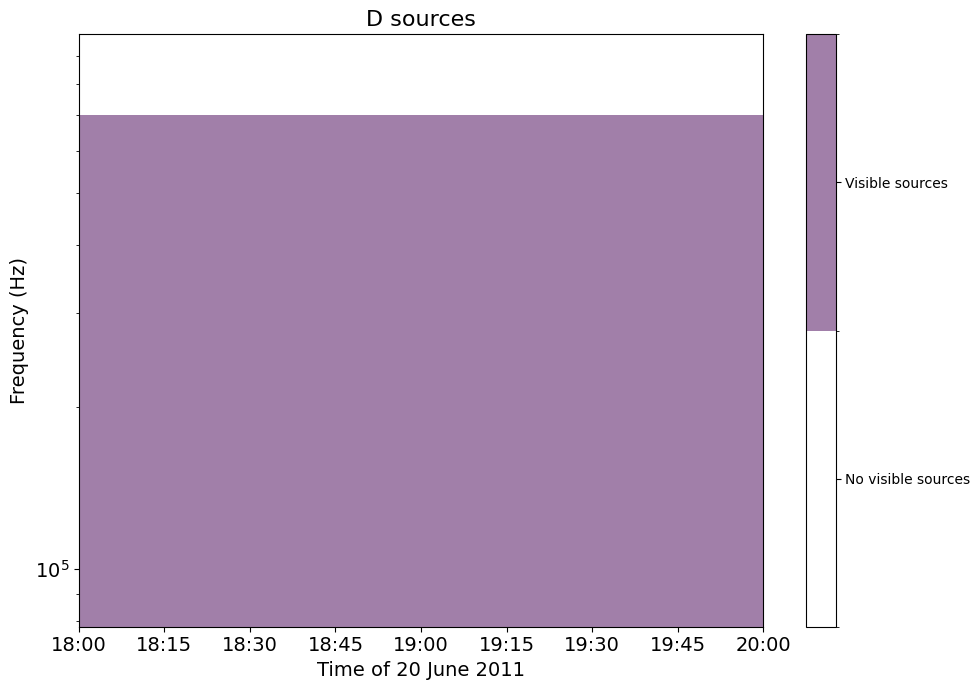

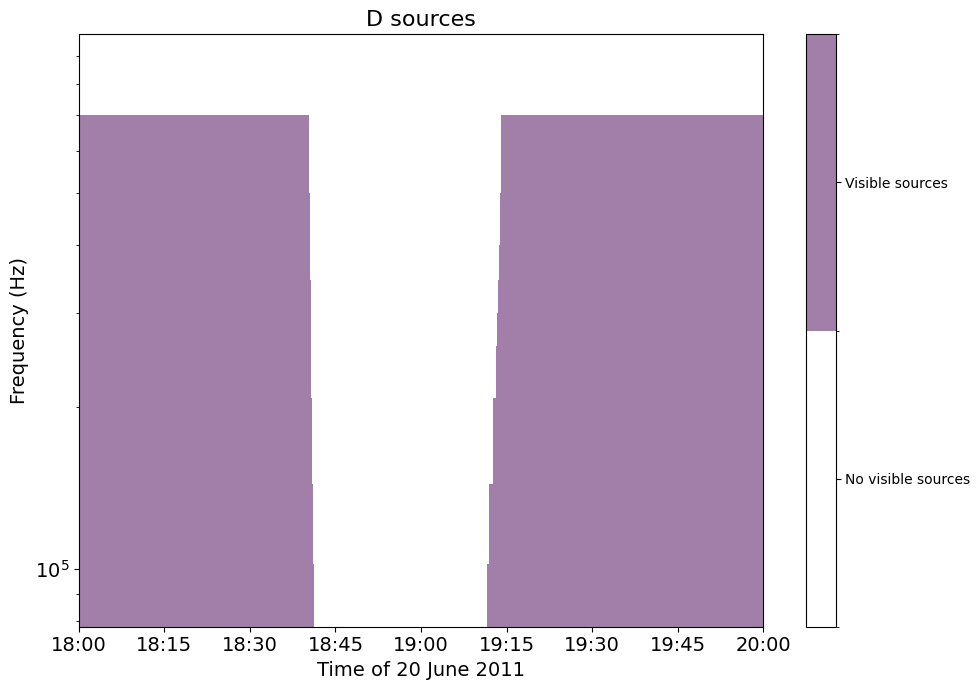

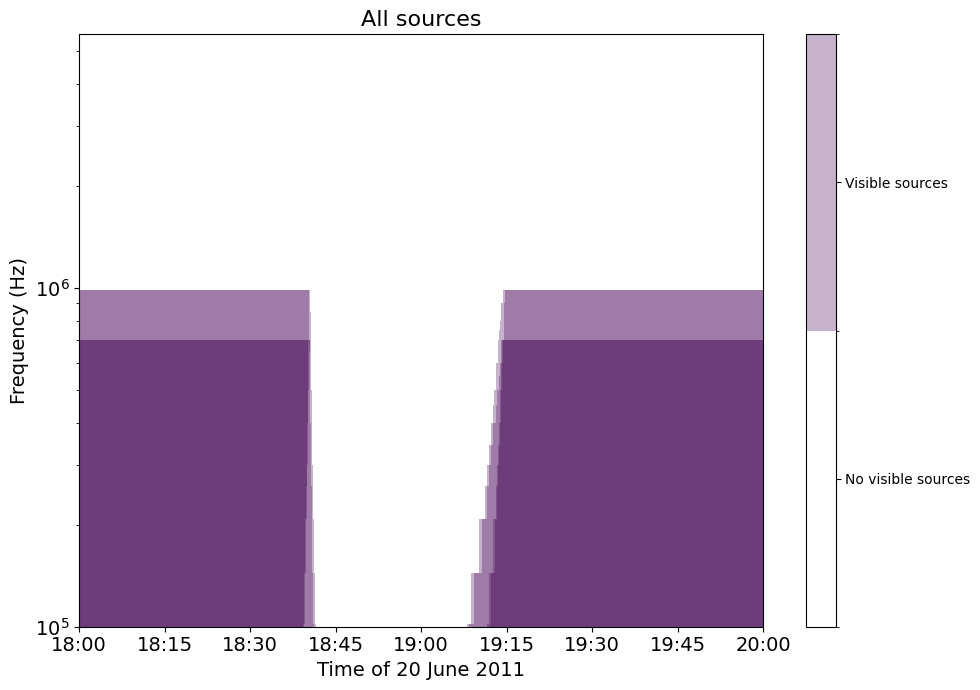

(datetime.datetime(2011, 6, 20, 18, 0), datetime.datetime(2011, 6, 20, 20, 0))


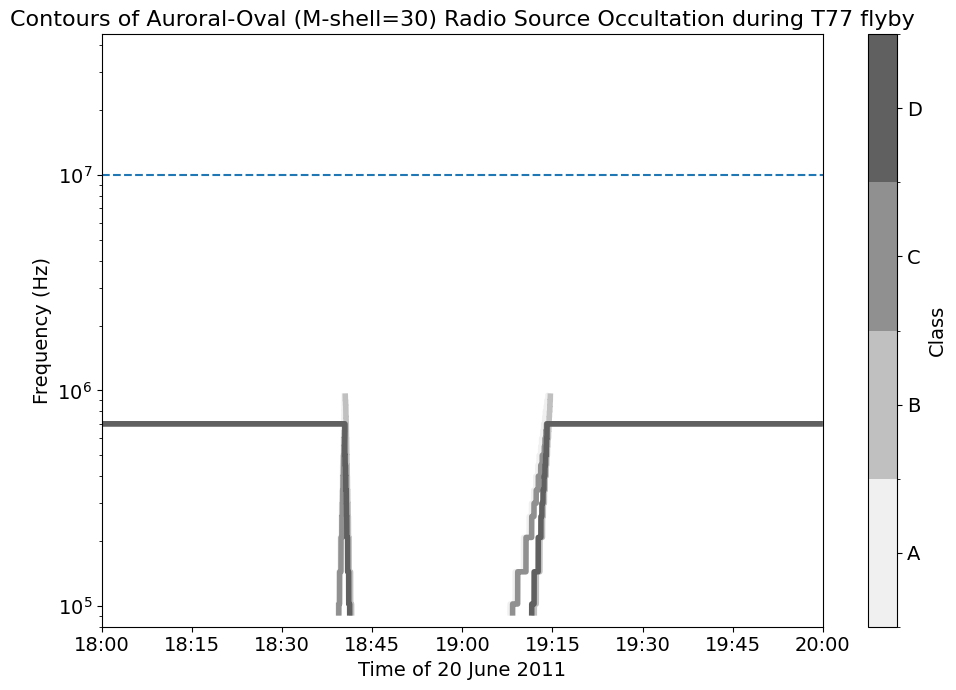

In [48]:
occultation.full_plots(flyby_name, expres_file=cdf_file_path, frequency_to_look_at = frequency_to_look_at)